# IND320, Assignment 3

## By: Ole Andreas Grøtting
Github: [IND320 - OLEGRO99](https://github.com/olegro99/IND320-OLEGRO99.git)\
Streamlit: https://ind320-olegro99-ybwpxf3ssrwyekrthttcuc.streamlit.app/

# log
I started by retriving the data from the webside and downloading the shp files. I had some problems with 1000 points at the start so i had to implement a batch size for loading the different regions. I also had to rename the region RÃ into RØ for making it easier to plot and work with. Then i combined RS+RØ into east and RM+RN into north. I then made a dictonary ro store the coordinates for both shp files and then made a function which loaded the wheater data using the API. I did some data cleaning and checked for missing values in the different regions and then i combined them all into a single dataframe and loaded the NO 3 data.

I then ploted the average precipitation as a function of time like in the lecture. Then i found the outliers using DCT to create SATV and ploted the outliers using the upper control limit and red dots as the outliers. I then created a function which also showed: Total observations, Number of outliers, Percentage of outliers, DCT frequency cutoff, Number of standard deviations, Upper control limit (median + threshold) and Robust standard deviation.  

The average temperature was plotted as a function of time. The Local Outlier Factor (LOF) algorithm was used to identify potential temperature anomalies. The proportion of outliers was included as a function parameter, with a default value of 1%. The detected anomalies were highlighted in the plot to make them easier to identify. The function also returns a summary of the detected outliers, including their corresponding dates and temperature values. Finally, the function was tested using the temperature datase

The national reservoir filling data from the NVE API was used to perform an STL decomposition. The function separates the data into seasonal, trend and residual components. The seasonal smoother, trend smoother and robust option were set as parameters with default values. The function was tested using the national data.

A spectrogram was created using the same NVE data to examine frequency changes over time. Window length and overlap were added as parameters with default values of 52 and 26. The function returns the plot and was tested using the national data.

For the streamlit app i created wheater_functions.py for leaoding the weather data and then i created Weather.py, time_series_analysys and anomoly_analysis as the new pages aswell as i made a select bar for which regio u can choose.


# usage of AI
My usage of AI includes:
- Grammar and language: Used AI to improve grammar, spelling and the wording of explanations.
- Understanding code: Used AI to explain methods that I was unfamiliar with.
- Visualisation: Used AI to help create and improve plots, including STL decomposition and spectrograms.
- API integration: Used AI to understand how to retrieve data from the NVE API and process the returned data.
- Understanding methods: Used AI to explain statistical methods and techniques used in the assignment.
- Documentation: Used AI to help write explanations and improve the wording of comments and descriptions.


## Imports

In [102]:
import geopandas as gpd
import pandas as pd
import openmeteo_requests
import requests_cache
from retry_requests import retry
import matplotlib.pyplot as plt
from scipy.fft import dct, idct
import numpy as np
from statsmodels.tsa.seasonal import STL
from sklearn.neighbors import LocalOutlierFactor
from scipy.signal import spectrogram

# Initialize Open-Meteo client
openmeteo = openmeteo_requests.Client()

import time as time_module

## retrive data

In [2]:
#Read the shapefile from atlas.nve.no
#include all files
gdf = gpd.read_file("../NVE_Region.shp")

gdf_bud = gpd.read_file("../budområder.shp")

#generate K random points within each region
K = 100 # Number of random points to generate per region
points_per_region = gdf['geometry'].sample_points(size=K, random_state=42)

# Transform WGS84 for latitude and longitude
points_wgs84 = points_per_region.to_crs(epsg=4326)

#fixing the encoding issue for the region name
gdf["REGION"] = gdf["REGION"].replace({
    "RÃ": "RØ"
})

#extract the coordinates and print them
for idx, multipoint in points_wgs84.items():
    region_name = gdf.loc[idx, 'REGION']
    print(f"Region: {region_name}")
    lat = ""
    lon = ""
    for point in multipoint.geoms:
        # Do something more useful with the coordinates
        lat = lat + ","+ str(point.y)
        lon = lon + ","+ str(point.x)


gdf["AREA"] = gdf["REGION"].replace({
    "RS": "East",
    "RØ": "East",
    "RM": "North",
    "RN": "North",
    "RV": "West",
})



Region: RV
Region: RM
Region: RN
Region: RØ
Region: RS


In [3]:
# Store coordinates in a dictionary
coordinates = {}

for idx, multipoint in points_wgs84.items():

    region_name = gdf.loc[idx, "AREA"]

    if region_name not in coordinates:
        coordinates[region_name] = []

    for point in multipoint.geoms:
        coordinates[region_name].append({
            "latitude": point.y,
            "longitude": point.x
        })

# Sample random points from each electricity area
K = 100

points_bud = gdf_bud.geometry.sample_points(
    size=K,
    random_state=42
)

# Convert points to WGS84
points_bud_wgs84 = points_bud.to_crs(epsg=4326)

# Store coordinates in a dictionary
coordinates_bud = {}

for idx, multipoint in points_bud_wgs84.items():

    region_name = gdf_bud.loc[idx, "budomr"]

    if region_name not in coordinates_bud:
        coordinates_bud[region_name] = []

    for point in multipoint.geoms:
        coordinates_bud[region_name].append({
            "latitude": point.y,
            "longitude": point.x
        })

In [56]:
lat[1:]

'60.798621065931655,59.686114875577246,59.36823066390626,58.831073153663546,59.11306566382285,58.39952160376174,60.6476941936885,59.207490110372035,59.0520214841243,59.37473649032095,58.86658660357142,59.4714157842179,60.529470262733945,57.878873099885126,59.28624259158553,58.81112543852483,58.51747873963468,60.41541521014433,59.96976505682891,59.27425258374419,59.27218228792572,59.47130662366801,59.10203699610034,58.582632699083,58.54160271034404,58.85173319209582,59.28754238650304,59.21383970194092,57.84754829672925,58.61081211261199,59.73673192632384,60.506325901843326,58.20515594977796,58.814000106162915,59.53029186969135,59.402121423090676,60.571010016706126,58.509031749885835,60.53373670192249,60.43233064092264,58.444078996914634,57.87607965840707,58.40476063125107,58.71092933594433,59.22121652454104,59.98091528492581,59.626388779786694,59.56506326739585,60.380131050880564,59.75916723959921,60.517684659400615,59.448645104469,58.774838844127714,60.52073455353545,60.71380546768425,

## Function for regions and timeperiods

In [28]:
def download_weather(region, start_date, end_date, coordinates, batch_size=10):

    # Get coordinates for selected region
    region_coordinates = coordinates[region]

    all_data = []

    # Download coordinates in smaller batches
    for batch_start in range(0, len(region_coordinates), batch_size):

        batch = region_coordinates[batch_start:batch_start + batch_size]

        latitudes = [p["latitude"] for p in batch]
        longitudes = [p["longitude"] for p in batch]

        # API parameters
        params = {
            "latitude": latitudes,
            "longitude": longitudes,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": [
                "temperature_2m",
                "precipitation",
                "relative_humidity_2m",
                "wind_speed_10m"
            ],
            "models": "era5"
        }

        # Download data
        responses = openmeteo.weather_api(
            "https://archive-api.open-meteo.com/v1/archive",
            params=params
        )

        # Process each location
        for i, response in enumerate(responses):

            hourly = response.Hourly()

            temperature = hourly.Variables(0).ValuesAsNumpy()
            precipitation = hourly.Variables(1).ValuesAsNumpy()
            humidity = hourly.Variables(2).ValuesAsNumpy()
            wind_speed = hourly.Variables(3).ValuesAsNumpy()

            time = pd.date_range(
                start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                freq=pd.Timedelta(seconds=hourly.Interval()),
                inclusive="left"
            )

            hourly_data = pd.DataFrame({
                "time": time,
                "region": region,
                "location_id": batch_start + i,
                "latitude": response.Latitude(),
                "longitude": response.Longitude(),
                "temperature_2m": temperature,
                "precipitation": precipitation,
                "relative_humidity_2m": humidity,
                "wind_speed_10m": wind_speed
            })

            all_data.append(hourly_data)

        print(f"Downloaded {min(batch_start + batch_size, len(region_coordinates))} "
              f"/ {len(region_coordinates)} locations for {region}")

        # Wait 15 seconds before the next batch
        time_module.sleep(15)

    return pd.concat(all_data, ignore_index=True)

## testing the function for all regions

In [12]:
#testing the function for East region
east_weather = download_weather(
    region="East",
    start_date="2026-10-12",
    end_date="2026-10-26",
    coordinates=coordinates
)

print(east_weather.head())

Downloaded 10 / 200 locations for East
Downloaded 20 / 200 locations for East
Downloaded 30 / 200 locations for East
Downloaded 40 / 200 locations for East
Downloaded 50 / 200 locations for East
Downloaded 60 / 200 locations for East
Downloaded 70 / 200 locations for East
Downloaded 80 / 200 locations for East
Downloaded 90 / 200 locations for East
Downloaded 100 / 200 locations for East
Downloaded 110 / 200 locations for East
Downloaded 120 / 200 locations for East
Downloaded 130 / 200 locations for East
Downloaded 140 / 200 locations for East
Downloaded 150 / 200 locations for East
Downloaded 160 / 200 locations for East
Downloaded 170 / 200 locations for East
Downloaded 180 / 200 locations for East
Downloaded 190 / 200 locations for East
Downloaded 200 / 200 locations for East
                       time region  location_id  latitude  longitude  \
0 2026-10-12 00:00:00+00:00   East            0      61.5      11.25   
1 2026-10-12 01:00:00+00:00   East            0      61.5      11

In [13]:
#testing the function for North region
north_weather = download_weather(
    region="North",
    start_date="2026-10-12",
    end_date="2026-10-26",
    coordinates=coordinates
)

print(north_weather.head())

Downloaded 10 / 200 locations for North
Downloaded 20 / 200 locations for North
Downloaded 30 / 200 locations for North
Downloaded 40 / 200 locations for North
Downloaded 50 / 200 locations for North
Downloaded 60 / 200 locations for North
Downloaded 70 / 200 locations for North
Downloaded 80 / 200 locations for North
Downloaded 90 / 200 locations for North
Downloaded 100 / 200 locations for North
Downloaded 110 / 200 locations for North
Downloaded 120 / 200 locations for North
Downloaded 130 / 200 locations for North
Downloaded 140 / 200 locations for North
Downloaded 150 / 200 locations for North
Downloaded 160 / 200 locations for North
Downloaded 170 / 200 locations for North
Downloaded 180 / 200 locations for North
Downloaded 190 / 200 locations for North
Downloaded 200 / 200 locations for North
                       time region  location_id  latitude  longitude  \
0 2026-10-12 00:00:00+00:00  North            0      64.0      11.75   
1 2026-10-12 01:00:00+00:00  North           

In [7]:
#check for missing values in the North region weather data
print(north_weather.isnull().sum())

time                    0
region                  0
location_id             0
latitude                0
longitude               0
temperature_2m          0
precipitation           0
relative_humidity_2m    0
wind_speed_10m          0
dtype: int64


In [14]:
west_weather = download_weather(
    region="West",
    start_date="2026-10-12",
    end_date="2026-10-26",
    coordinates=coordinates
)

print(west_weather.head())

Downloaded 10 / 100 locations for West
Downloaded 20 / 100 locations for West
Downloaded 30 / 100 locations for West
Downloaded 40 / 100 locations for West
Downloaded 50 / 100 locations for West
Downloaded 60 / 100 locations for West
Downloaded 70 / 100 locations for West
Downloaded 80 / 100 locations for West
Downloaded 90 / 100 locations for West
Downloaded 100 / 100 locations for West
                       time region  location_id  latitude  longitude  \
0 2026-10-12 00:00:00+00:00   West            0      62.5       8.75   
1 2026-10-12 01:00:00+00:00   West            0      62.5       8.75   
2 2026-10-12 02:00:00+00:00   West            0      62.5       8.75   
3 2026-10-12 03:00:00+00:00   West            0      62.5       8.75   
4 2026-10-12 04:00:00+00:00   West            0      62.5       8.75   

   temperature_2m  precipitation  relative_humidity_2m  wind_speed_10m  
0          -1.954            0.0             79.639282        6.452441  
1          -2.454            0

In [77]:
#chewck for missing values in the West region weather data
print(west_weather.isnull().sum())

time                    0
region                  0
location_id             0
latitude                0
longitude               0
temperature_2m          0
precipitation           0
relative_humidity_2m    0
wind_speed_10m          0
dtype: int64


In [15]:
# Combine the weather data from all regions into a single DataFrame
weather_data = pd.concat(
    [east_weather, north_weather, west_weather],
    ignore_index=True
)

In [16]:
#check for missing values in the North region weather data
print(north_weather.isnull().sum())

time                    0
region                  0
location_id             0
latitude                0
longitude               0
temperature_2m          0
precipitation           0
relative_humidity_2m    0
wind_speed_10m          0
dtype: int64


In [17]:
#printing information about the combined weather data
print(weather_data.shape)

#printing the count of each region
print(weather_data["region"].value_counts())

(180000, 9)
region
East     72000
North    72000
West     36000
Name: count, dtype: int64


In [18]:
#check for missing values in the combined weather data
print(weather_data.isna().sum())

print(weather_data.head())

time                    0
region                  0
location_id             0
latitude                0
longitude               0
temperature_2m          0
precipitation           0
relative_humidity_2m    0
wind_speed_10m          0
dtype: int64
                       time region  location_id  latitude  longitude  \
0 2026-10-12 00:00:00+00:00   East            0      61.5      11.25   
1 2026-10-12 01:00:00+00:00   East            0      61.5      11.25   
2 2026-10-12 02:00:00+00:00   East            0      61.5      11.25   
3 2026-10-12 03:00:00+00:00   East            0      61.5      11.25   
4 2026-10-12 04:00:00+00:00   East            0      61.5      11.25   

   temperature_2m  precipitation  relative_humidity_2m  wind_speed_10m  
0         -0.5795            0.0             91.925171        1.853213  
1         -0.4295            0.0             91.261513        2.012461  
2         -0.8295            0.0             92.588875        1.980000  
3         -0.5295           

In [29]:
# Download data for NO3 for 2024
data_NO3 = download_weather(
    region="NO 3",
    start_date="2024-01-01",
    end_date="2024-12-31",
    coordinates=coordinates_bud,
    batch_size=25
)

print(data_NO3.head())

Downloaded 25 / 100 locations for NO 3
Downloaded 50 / 100 locations for NO 3
Downloaded 75 / 100 locations for NO 3
Downloaded 100 / 100 locations for NO 3
                       time region  location_id  latitude  longitude  \
0 2024-01-01 00:00:00+00:00   NO 3            0     62.25       7.25   
1 2024-01-01 01:00:00+00:00   NO 3            0     62.25       7.25   
2 2024-01-01 02:00:00+00:00   NO 3            0     62.25       7.25   
3 2024-01-01 03:00:00+00:00   NO 3            0     62.25       7.25   
4 2024-01-01 04:00:00+00:00   NO 3            0     62.25       7.25   

   temperature_2m  precipitation  relative_humidity_2m  wind_speed_10m  
0         -3.7145            0.0             66.674316       11.808878  
1         -4.0145            0.0             66.867294       12.313894  
2         -4.1645            0.0             66.310432       12.313894  
3         -4.1645            0.0             65.019623       12.599998  
4         -3.9645            0.0             

## plots

In [31]:
# Create a date column from the time column
data_NO3["date"] = data_NO3["time"].dt.date

# Sum the rain for each day
daily_location = (
    data_NO3.groupby(["date", "location_id"])["precipitation"]
    .sum()
    .reset_index()
)
daily_location.head()

,date,location_id,precipitation
0,2024-01-01,0,0.0
1,2024-01-01,1,0.4
2,2024-01-01,2,0.0
3,2024-01-01,3,0.0
4,2024-01-01,4,0.0


In [32]:
# Calcualte the average precipitation for each day
average_precipitation = daily_location.groupby("date")["precipitation"].mean().reset_index()
average_precipitation.head()

,date,precipitation
0,2024-01-01,0.117
1,2024-01-02,0.086
2,2024-01-03,0.003
3,2024-01-04,0.332
4,2024-01-05,1.418


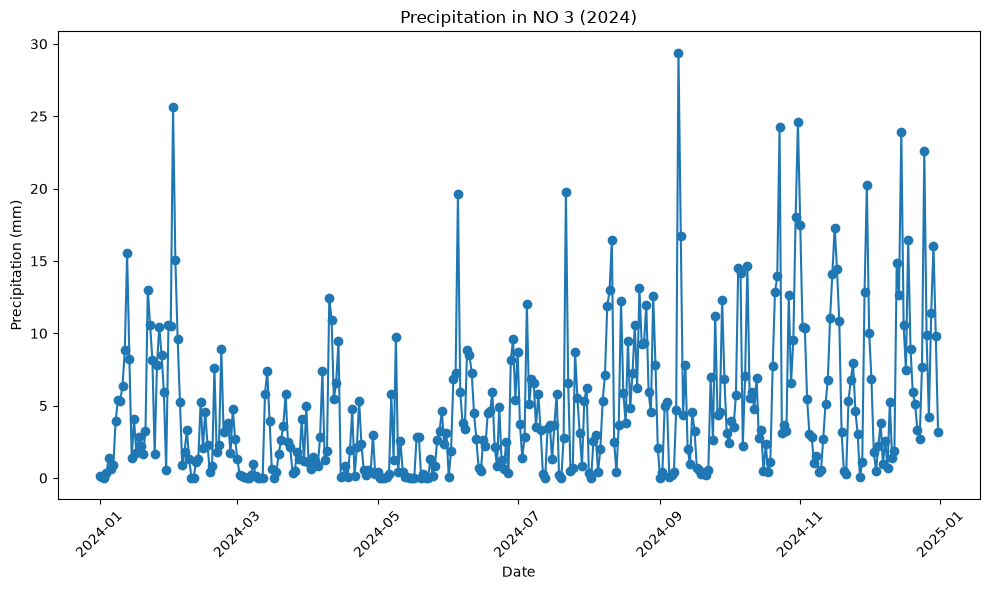

In [33]:

# Plot the average precipitation as a function of time
plt.figure(figsize=(10, 6))
plt.plot(average_precipitation["date"], average_precipitation["precipitation"], marker="o", linestyle="-")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.title("Precipitation in NO 3 (2024)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## DCT

In [34]:
# Extract daily average precipitation as a NumPy array
signal = average_precipitation["precipitation"].values

# Number of observations (366 days in 2024)
N = len(signal)

# Transform the precipitation signal from the time domain to the frequency domain
dct_signal = dct(signal, type=2, norm="ortho")

In [35]:
# Choose how many low-frequency components to remove
# A higher cutoff removes more slow variations from the signal
cutoff = 10

# Make a copy of the DCT coefficients
filtered_dct = dct_signal.copy()

# Remove the first 10 coefficients (low-frequency components)
# These components mainly represent slow changes and seasonal patterns
filtered_dct[:cutoff] = 0

# Transform the filtered coefficients back to the time domain
# This gives us the high-pass filtered precipitation signal
filtered_signal = idct(filtered_dct, type=2, norm="ortho")

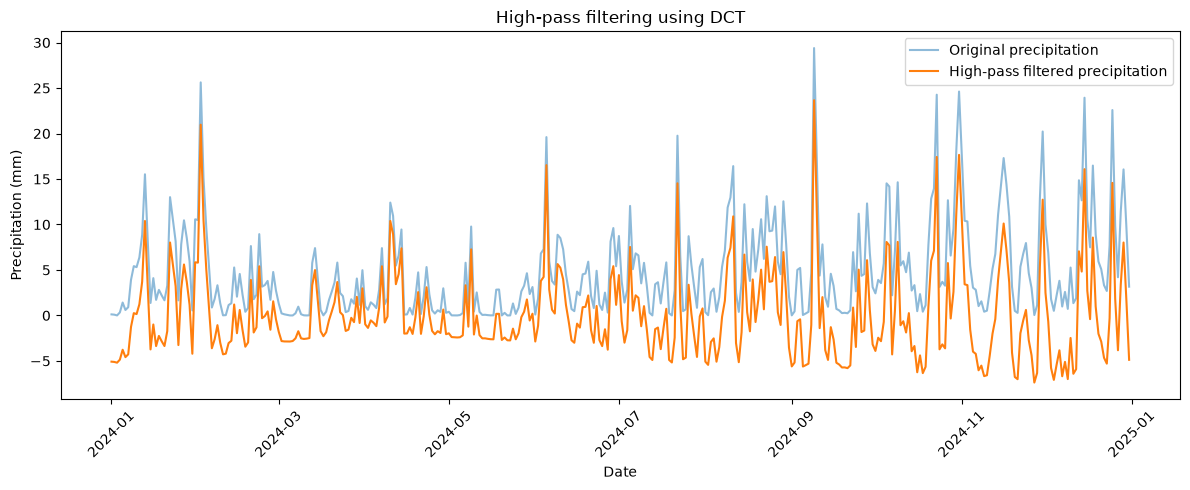

In [36]:
plt.figure(figsize=(12, 5))

# Plot the original daily average precipitation
plt.plot(
    average_precipitation["date"],
    signal,
    label="Original precipitation",
    alpha=0.5
)

# Plot the high-pass filtered precipitation
plt.plot(
    average_precipitation["date"],
    filtered_signal,
    label="High-pass filtered precipitation"
)

# Add labels and title
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.title("High-pass filtering using DCT")

# Display legend and format the x-axis
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## SPC

In [37]:
# Calculate the median of SATV
satv_median = np.median(filtered_signal)

# Calculate the Median Absolute Deviation (MAD)
mad = np.median(np.abs(filtered_signal - satv_median))

# Convert MAD to a robust estimate of standard deviation
robust_std = 1.4826 * mad

# Calculate Statistical Process Control (SPC) limits
ucl = satv_median + 3 * robust_std  # Upper Control Limit
lcl = satv_median - 3 * robust_std  # Lower Control Limit

print("Upper Control Limit:", ucl)
print("Lower Control Limit:", lcl)

Upper Control Limit: 8.815489
Lower Control Limit: -11.233156


In [38]:
# Identify outliers based on SATV
outliers = (filtered_signal > ucl) | (filtered_signal < lcl)

# Store the results in the dataframe
average_precipitation["outlier"] = outliers

# Count the number of outliers
print("Number of outliers:", outliers.sum())

Number of outliers: 18


In [40]:
# Calculate low-frequency component
baseline = signal - filtered_signal

# Calculate robust control limits from SATV
median = np.median(filtered_signal)
mad = np.median(np.abs(filtered_signal - median))
robust_std = 1.4826 * mad

ucl = median + 3 * robust_std
lcl = median - 3 * robust_std

# Convert control limits to precipitation scale
upper_boundary = baseline + ucl
lower_boundary = baseline + lcl

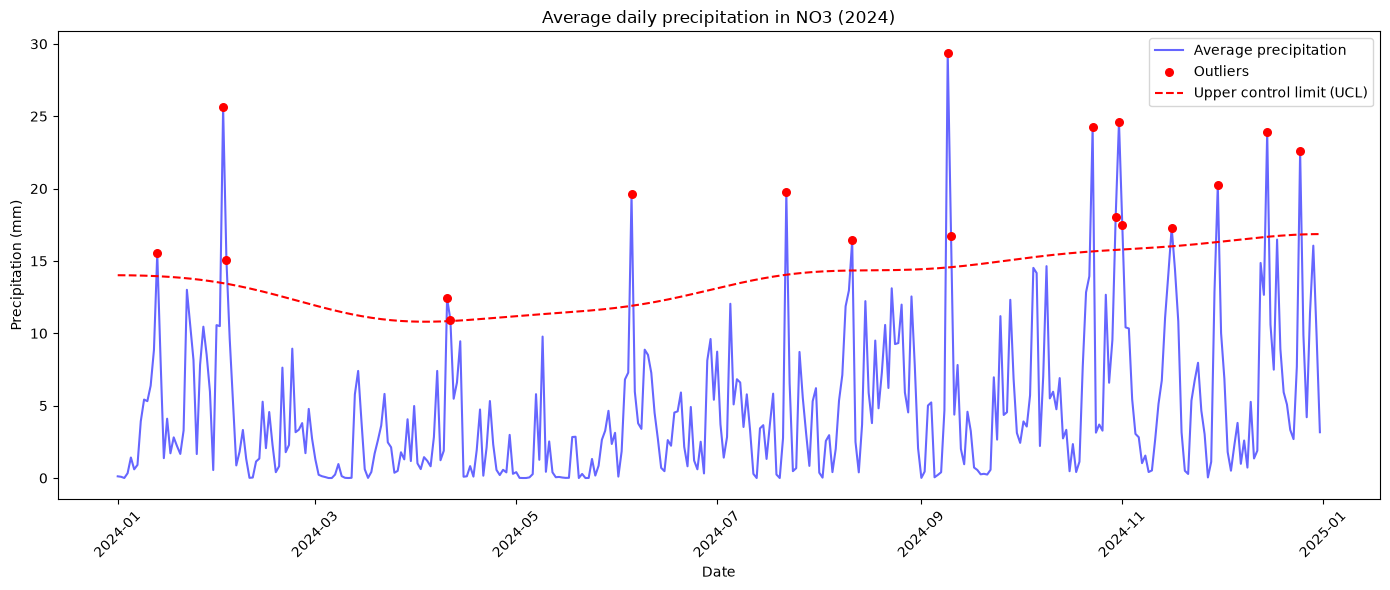

In [42]:
plt.figure(figsize=(14, 6))

# Plot average precipitation
plt.plot(
    average_precipitation["date"],
    average_precipitation["precipitation"],
    color="blue",
    alpha=0.6,
    label="Average precipitation"
)

# Highlight outliers in red
plt.scatter(
    average_precipitation.loc[outliers, "date"],
    average_precipitation.loc[outliers, "precipitation"],
    color="red",
    s=30,
    label="Outliers",
    zorder=3
)

# Plot upper and lower control limits
plt.plot(
    average_precipitation["date"],
    upper_boundary,
    color="red",
    linestyle="--",
    label="Upper control limit (UCL)"
)

# Labels and title
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.title("Average daily precipitation in NO3 (2024)")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## DCT cutoff

In [43]:
def plot_precipitation_outliers(data, cutoff=10, n_std=3):

    # Extract precipitation values
    signal = data["precipitation"].values
    dates = data["date"]

    # Apply Discrete Cosine Transform
    dct_signal = dct(signal, type=2, norm="ortho")

    # Remove low-frequency components (high-pass filter)
    filtered_dct = dct_signal.copy()
    filtered_dct[:cutoff] = 0

    # Inverse DCT to obtain SATV
    satv = idct(filtered_dct, type=2, norm="ortho")

    # Calculate robust statistics using the whole year
    median = np.median(satv)
    mad = np.median(np.abs(satv - median))
    robust_std = 1.4826 * mad

    # Calculate upper control limit
    ucl = median + n_std * robust_std

    # Calculate low-frequency component
    baseline = signal - satv

    # Convert UCL to precipitation scale
    upper_boundary = baseline + ucl

    # Identify outliers
    outliers = satv > ucl

    # Create a copy of the data with outlier information
    results = data.copy()
    results["outlier"] = outliers

    # Extract outlier observations
    outlier_data = results[results["outlier"]].copy()

    # Create summary of outliers
    summary = {
        "Total observations": len(data),
        "Number of outliers": int(outliers.sum()),
        "Percentage of outliers": round(outliers.mean() * 100, 2),
        "DCT frequency cutoff": cutoff,
        "Number of standard deviations": n_std,
        "Upper control limit (median + threshold)": ucl,
        "Robust standard deviation": robust_std
    }

    # Create plot
    fig, ax = plt.subplots(figsize=(14, 6))

    # Plot average precipitation
    ax.plot(
        dates,
        signal,
        color="blue",
        alpha=0.6,
        label="Average precipitation"
    )

    # Highlight outliers
    ax.scatter(
        results.loc[outliers, "date"],
        results.loc[outliers, "precipitation"],
        color="red",
        s=30,
        label="Outliers",
        zorder=3
    )

    # Plot upper control limit
    ax.plot(
        dates,
        upper_boundary,
        color="red",
        linestyle="--",
        label="Upper control limit (UCL)"
    )

    # Add labels and title
    ax.set_xlabel("Date")
    ax.set_ylabel("Precipitation (mm)")
    ax.set_title("Average daily precipitation and outliers in NO3 (2024)")
    ax.legend()

    plt.xticks(rotation=45)
    plt.tight_layout()

    return fig, summary, outlier_data

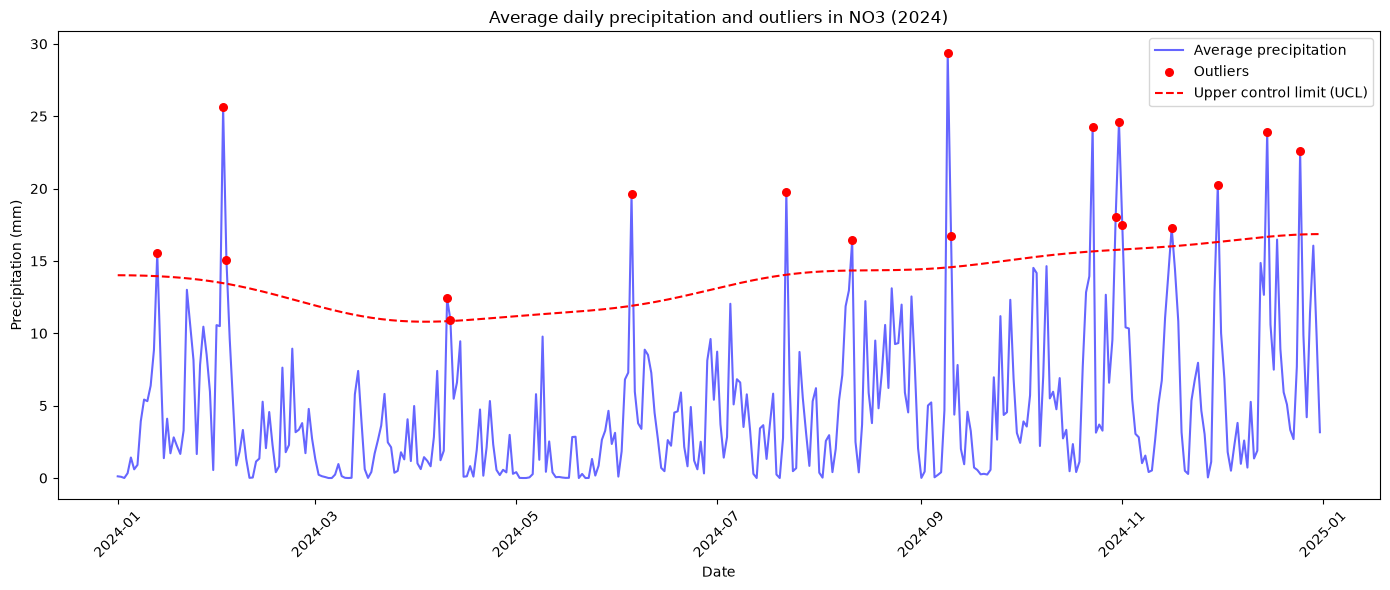

{'Total observations': 366, 'Number of outliers': 18, 'Percentage of outliers': np.float64(4.92), 'DCT frequency cutoff': 10, 'Number of standard deviations': 3, 'Upper control limit (median + threshold)': np.float32(8.815489), 'Robust standard deviation': np.float32(3.341441)}
           date  precipitation  outlier
12   2024-01-13      15.518001     True
32   2024-02-02      25.622000     True
33   2024-02-03      15.095000     True
100  2024-04-10      12.406000     True
101  2024-04-11      10.948001     True
156  2024-06-05      19.605999     True
203  2024-07-22      19.760000     True
223  2024-08-11      16.417000     True
252  2024-09-09      29.396002     True
253  2024-09-10      16.740999     True
296  2024-10-23      24.268000     True
303  2024-10-30      18.062000     True
304  2024-10-31      24.615000     True
305  2024-11-01      17.510000     True
320  2024-11-16      17.299999     True
334  2024-11-30      20.222000     True
349  2024-12-15      23.934999     True
3

In [44]:
# Test the function with default parameters
fig, summary, outlier_data = plot_precipitation_outliers(
    average_precipitation
)

# Display plot
plt.show()

# Display summary
print(summary)

# Display outlier observations
print(outlier_data)

## average temperature as a function off time

In [46]:
# Extract date from timestamp
data_NO3["date"] = data_NO3["time"].dt.date

# Calculate average temperature per day and location
daily_temperature = (
    data_NO3.groupby(["date", "location_id"])["temperature_2m"]
    .mean()
    .reset_index()
)

# Calculate average temperature across all locations per day
average_temperature = (
    daily_temperature.groupby("date")["temperature_2m"]
    .mean()
    .reset_index()
)

In [48]:
def plot_temperature_anomalies(data, contamination=0.01, n_neighbors=20):

    # Sort data by date
    data = data.sort_values("date").copy()

    # Remove missing temperature values
    data = data.dropna(subset=["temperature_2m"]).copy()

    # Extract temperature values
    temperature = data["temperature_2m"].values.reshape(-1, 1)

    # Initialize Local Outlier Factor
    lof = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination
    )

    # Identify anomalies
    predictions = lof.fit_predict(temperature)

    # LOF returns -1 for outliers and 1 for inliers
    anomalies = predictions == -1

    # Store results in a copy of the data
    results = data.copy()
    results["anomaly"] = anomalies
    results["LOF_score"] = lof.negative_outlier_factor_

    # Extract anomaly observations
    anomaly_data = results[results["anomaly"]].copy()

    # Create summary
    summary = {
        "Total observations": len(results),
        "Number of anomalies": int(anomalies.sum()),
        "Percentage of anomalies": round(anomalies.mean() * 100, 2),
        "Contamination": contamination,
        "Number of neighbours": n_neighbors
    }

    # Create plot
    fig, ax = plt.subplots(figsize=(14, 6))

    # Plot average temperature
    ax.plot(
        results["date"],
        results["temperature_2m"],
        color="blue",
        alpha=0.6,
        label="Average temperature"
    )

    # Highlight anomalies
    ax.scatter(
        anomaly_data["date"],
        anomaly_data["temperature_2m"],
        color="red",
        s=30,
        label="Anomalies (LOF)",
        zorder=3
    )

    # Add labels and title
    ax.set_xlabel("Date")
    ax.set_ylabel("Temperature (°C)")
    ax.set_title("Average daily temperature and anomalies in NO3 (2024)")
    ax.legend()

    plt.xticks(rotation=45)
    plt.tight_layout()

    return fig, summary, anomaly_data

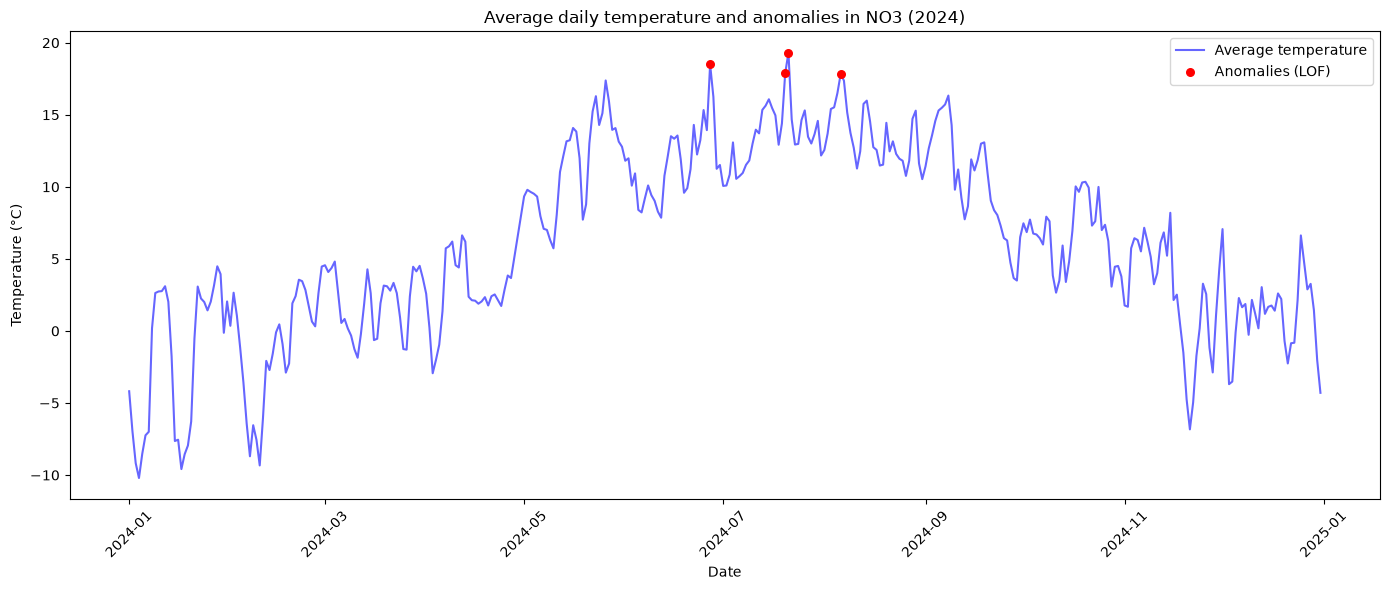

{'Total observations': 366, 'Number of anomalies': 4, 'Percentage of anomalies': np.float64(1.09), 'Contamination': 0.01, 'Number of neighbours': 20}
           date  temperature_2m  anomaly  LOF_score
178  2024-06-27       18.495140     True  -2.770082
201  2024-07-20       17.876745     True  -2.307917
202  2024-07-21       19.313017     True  -3.381331
218  2024-08-06       17.821558     True  -2.266672


In [49]:
# Test the function with default parameters (1% outliers)
fig, summary, anomaly_data = plot_temperature_anomalies(
    average_temperature
)

# Display plot
plt.show()

# Display summary
print(summary)

# Display anomaly observations
print(anomaly_data)

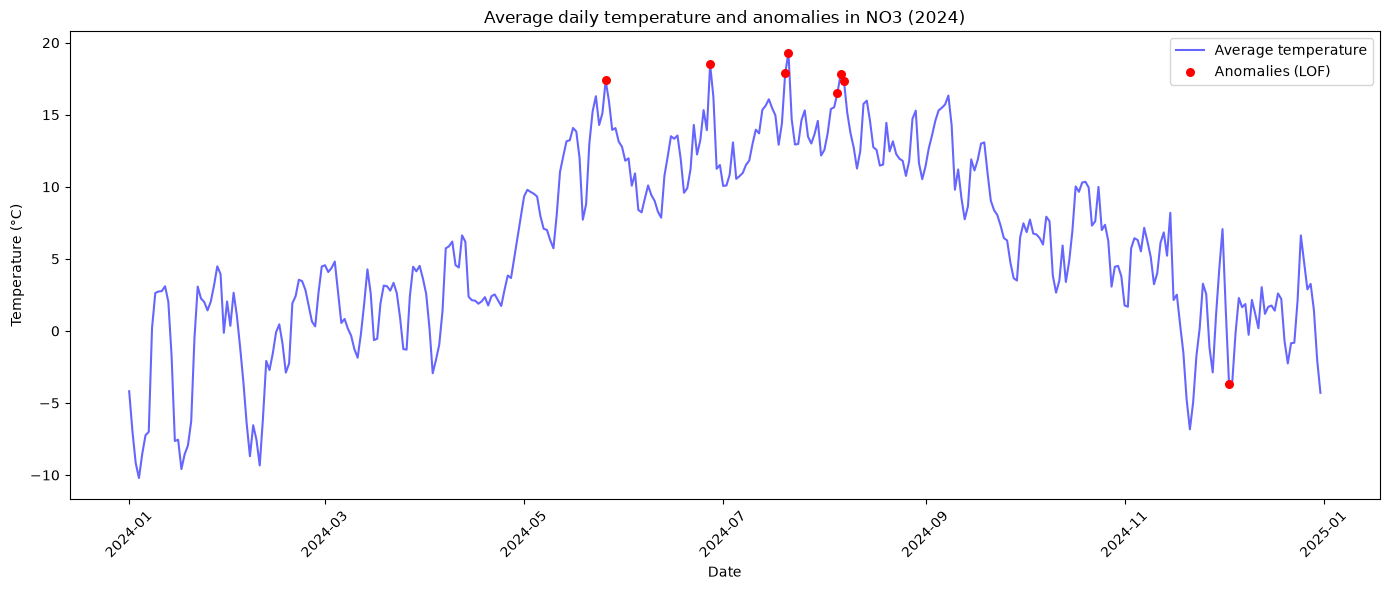

{'Total observations': 366, 'Number of anomalies': 8, 'Percentage of anomalies': np.float64(2.19), 'Contamination': 0.02, 'Number of neighbours': 20}


In [53]:
# Test the function with 2% expected outliers and 20 nearest neighbours
fig, summary, anomaly_data = plot_temperature_anomalies(
    average_temperature,
    contamination=0.02,  # Expected proportion of outliers (2%)
    n_neighbors=20       # Number of nearest neighbours used by LOF
)

# Display the temperature plot with highlighted anomalies
plt.show()

# Print a summary of the detected anomalies
print(summary)

## STL

In [80]:
# NVE Magasinstatistikk API
import requests


url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(url)
response.raise_for_status()

# Convert API response to a DataFrame
magasin_data = pd.DataFrame(response.json())

# Inspect the data
display(magasin_data.head())
print(magasin_data.columns)
print(magasin_data.shape)

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
1,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
2,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
3,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301
4,2017-11-05,EL,4,2017,44,0.794520,21.079208,16.747847,0001-01-01T00:00:00,0.804085,-0.009565


Index(['dato_Id', 'omrType', 'omrnr', 'iso_aar', 'iso_uke', 'fyllingsgrad',
       'kapasitet_TWh', 'fylling_TWh', 'neste_Publiseringsdato',
       'fyllingsgrad_forrige_uke', 'endring_fyllingsgrad'],
      dtype='str')
(14949, 11)


In [87]:
magasin_data["dato_Id"] = pd.to_datetime(
    magasin_data["dato_Id"], errors="coerce"
)

magasin_data["fylling_TWh"] = pd.to_numeric(
    magasin_data["fylling_TWh"], errors="coerce"
)

magasin_data["kapasitet_TWh"] = pd.to_numeric(
    magasin_data["kapasitet_TWh"], errors="coerce"
)

magasin_data = magasin_data.dropna(
    subset=["dato_Id", "fylling_TWh", "kapasitet_TWh"]
)

In [88]:
el_data = magasin_data[
    magasin_data["omrType"] == "EL"
].copy()

national_data = (
    el_data.groupby("dato_Id")
    .agg({
        "fylling_TWh": "sum",
        "kapasitet_TWh": "sum"
    })
    .reset_index()
)

national_data["fyllingsgrad"] = (
    national_data["fylling_TWh"] /
    national_data["kapasitet_TWh"]
)

national_data = national_data.sort_values("dato_Id").reset_index(drop=True)

     dato_Id  fylling_TWh  kapasitet_TWh  fyllingsgrad
0 1995-01-08    52.709612      87.437581      0.602826
1 1995-01-15    50.483397      87.437581      0.577365
2 1995-01-22    48.770680      87.437581      0.557777
3 1995-01-29    46.359929      87.437581      0.530206
4 1995-02-05    43.938996      87.437581      0.502518
dato_Id          datetime64[us]
fylling_TWh             float64
kapasitet_TWh           float64
fyllingsgrad            float64
dtype: object
dato_Id
7 days    1660
Name: count, dtype: int64


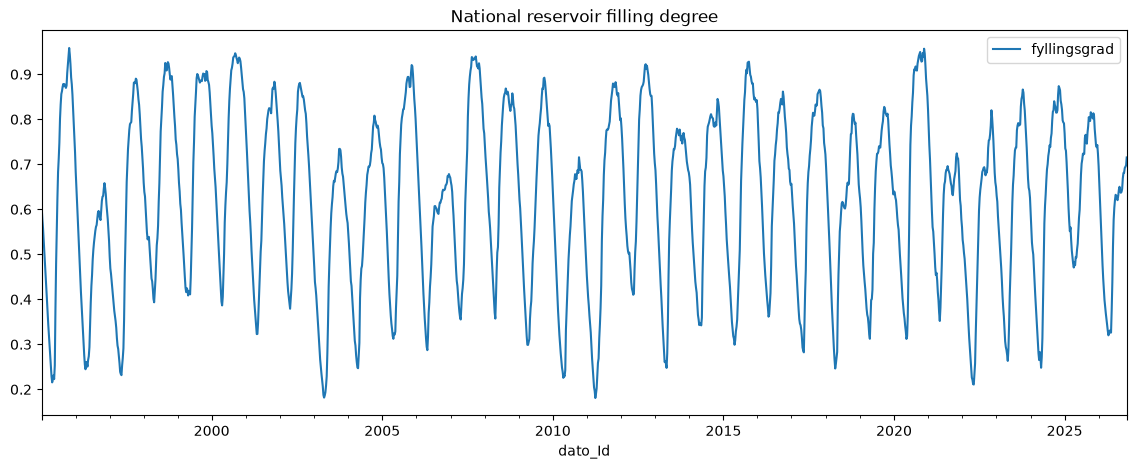

In [95]:
# Inspect the data
print(national_data.head())
print(national_data.dtypes)

# Check the time intervals
print(national_data["dato_Id"].diff().value_counts().head())

# Plot national filling degree
national_data.plot(
    x="dato_Id",
    y="fyllingsgrad",
    figsize=(14, 5),
    title="National reservoir filling degree"
)

plt.show()

In [97]:
def prepare_filling_data(data):

    # Select date and filling degree
    df = data[["dato_Id", "fyllingsgrad"]].copy()

    # Convert columns to appropriate data types
    df["dato_Id"] = pd.to_datetime(df["dato_Id"], errors="coerce")
    df["fyllingsgrad"] = pd.to_numeric(df["fyllingsgrad"], errors="coerce")

    # Remove missing observations
    df = df.dropna()

    # Sort observations by date
    df = df.sort_values("dato_Id")

    # Set date as index
    df = df.set_index("dato_Id")

    return df["fyllingsgrad"]

In [100]:
def plot_stl_decomposition(data, seasonal=13, trend=53, robust=True):

    # Prepare the filling degree time series
    filling = prepare_filling_data(data)

    # Perform STL decomposition
    stl = STL(
        filling,
        period=52,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    )

    # Fit the model
    result = stl.fit()

    # Plot the decomposition
    fig = result.plot()
    fig.set_size_inches(14, 10)

    # Add title
    fig.suptitle(
        "STL decomposition of reservoir filling degree",
        fontsize=14
    )

    fig.tight_layout()

    return fig

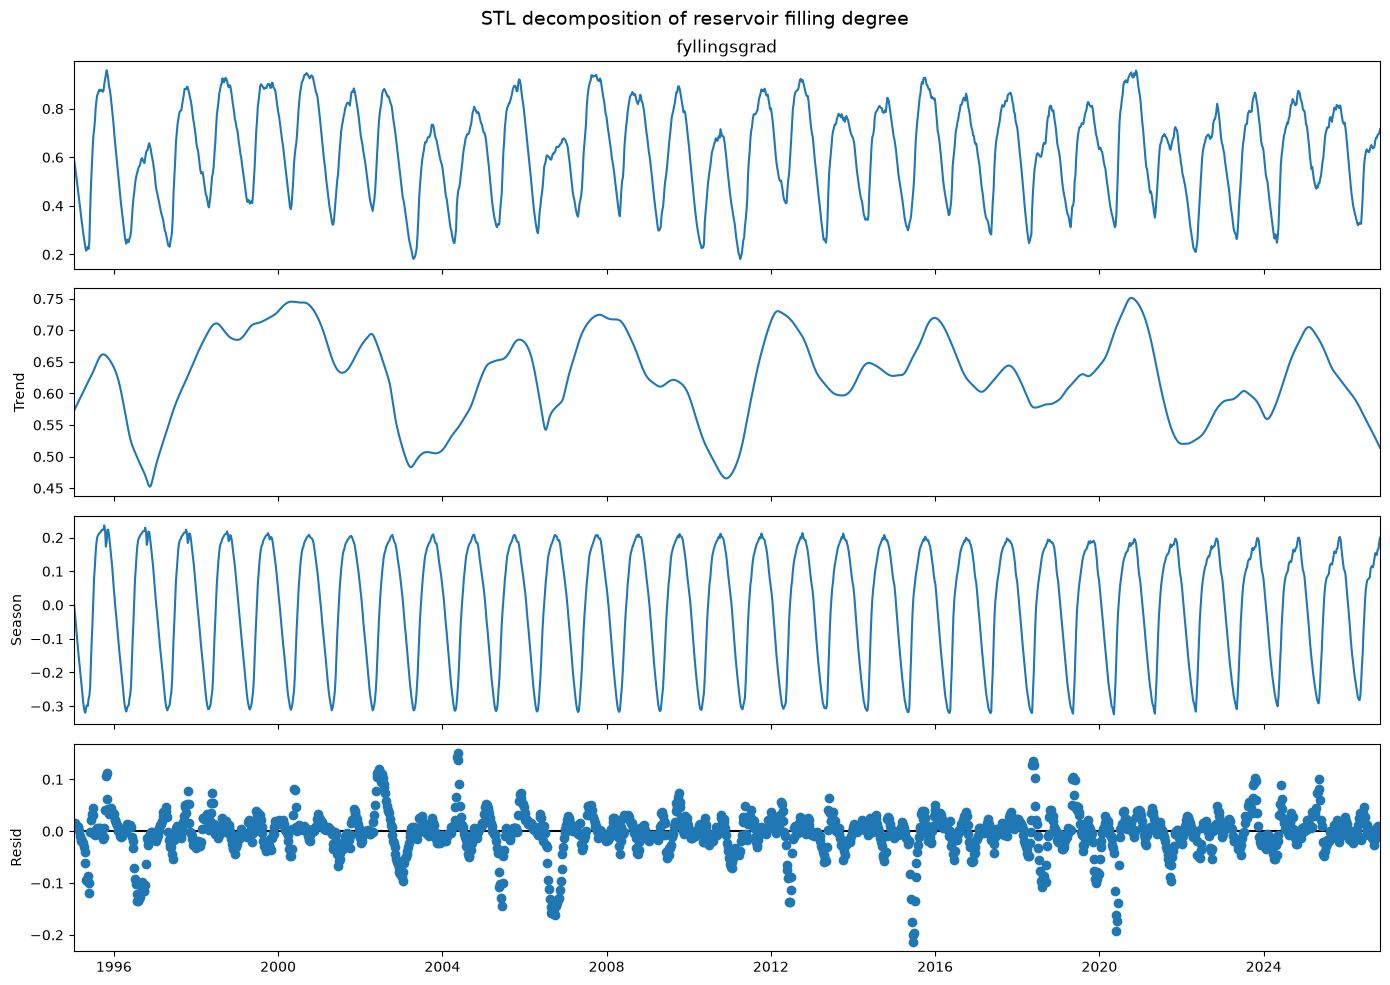

In [101]:
# Test the STL decomposition function
fig = plot_stl_decomposition(
    national_data,
    seasonal=13,
    trend=53,
    robust=True
)

plt.show()

## spectogram

In [103]:
def plot_filling_spectrogram(data, window_length=52, window_overlap=26):

    # Prepare the filling degree data
    filling = prepare_filling_data(data)

    # Calculate the spectrogram
    frequencies, times, power = spectrogram(
        filling.values,
        fs=1,
        nperseg=window_length,
        noverlap=window_overlap
    )

    # Convert time values to dates
    dates = filling.index[0] + pd.to_timedelta(times * 7, unit="D")

    # Plot the spectrogram
    plt.figure(figsize=(14, 6))
    plt.pcolormesh(
        dates,
        frequencies,
        10 * np.log10(power + 1e-12),
        shading="auto"
    )

    plt.xlabel("Date")
    plt.ylabel("Frequency (cycles per week)")
    plt.title("Spectrogram of reservoir filling degree")
    plt.colorbar(label="Power (dB)")
    plt.tight_layout()

    return plt.gcf()

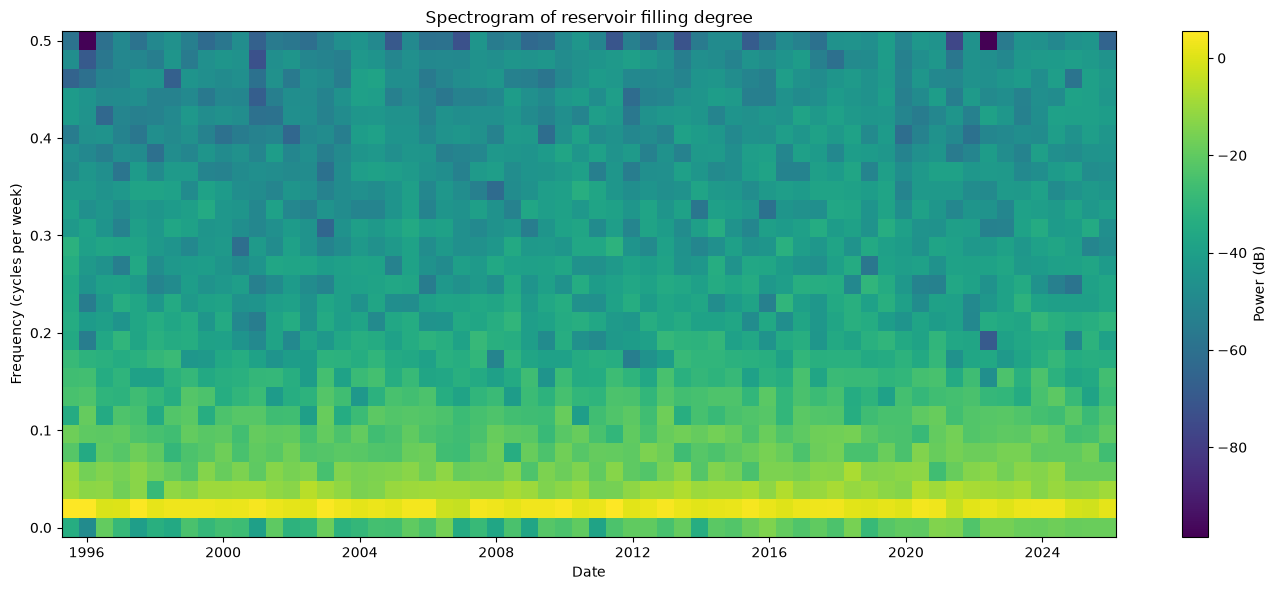

In [106]:
# Test the spectrogram function
fig = plot_filling_spectrogram(
    national_data,
    window_length=52,
    window_overlap=26
)

plt.show()